In [79]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.animation import FuncAnimation, PillowWriter


 1. DISTRIBUCIÓN OBJETIVO p_0(x)
    Mezcla de dos gaussianas en 2D


In [80]:
sigma0 = 0.35

means = np.array([
    [-2.0, 0.0],
    [ 2.0, 0.0]
])

weights = np.array([0.5, 0.5])

2. VP-SDE
dx = -1/2 beta(t) x dt + sqrt(beta(t)) dW

In [81]:

beta_min = 0.1
beta_max = 12.0


def beta(t):

    return beta_min + (beta_max - beta_min) * t


def integral_beta(t):
    """
    Integral desde 0 hasta t de beta(s) ds
    para un beta lineal.
    """

    return (
        beta_min * t
        +
        0.5 * (beta_max - beta_min) * t**2
    )


def alpha_bar(t):

    return np.exp(
        -integral_beta(t)
    )



3. DISTRIBUCIÓN p_t(x)
Si p_0 es una mezcla de gaussianas,
bajo la VP-SDE cada componente sigue siendo gaussiana.

In [82]:

def mixture_parameters_t(t):

    abar = alpha_bar(t)

    # Las medias se acercan al origen
    means_t = np.sqrt(abar) * means

    # La varianza aumenta hacia 1
    variance_t = (
        abar * sigma0**2
        +
        (1.0 - abar)
    )

    return means_t, variance_t

4. DENSIDAD p_t(x)

In [83]:
def density_mixture(x, t):
    """
    x tiene forma (..., 2)
    """

    means_t, variance_t = mixture_parameters_t(t)

    # (..., numero_componentes, 2)
    diff = (
        x[..., None, :]
        -
        means_t
    )

    gaussian_components = (

        np.exp(
            -0.5
            *
            np.sum(diff**2, axis=-1)
            /
            variance_t
        )

        /

        (2 * np.pi * variance_t)
    )

    density = np.sum(
        weights * gaussian_components,
        axis=-1
    )

    return density



5. SCORE ANALÍTICO

score(x,t) = grad_x log p_t(x)


In [84]:
def score_mixture(x, t):
    """
    Score exacto de una mezcla de gaussianas.

    x:
        (..., 2)

    return:
        (..., 2)
    """

    means_t, variance_t = mixture_parameters_t(t)

    diff = (
        x[..., None, :]
        -
        means_t
    )

    # Log-probabilidad de cada componente
    log_components = (

        -0.5
        *
        np.sum(diff**2, axis=-1)
        /
        variance_t

        -

        np.log(
            2 * np.pi * variance_t
        )

        +

        np.log(weights)
    )

    # Responsabilidades de cada gaussiana
    # Se usa esta resta por estabilidad numérica
    max_log = np.max(
        log_components,
        axis=-1,
        keepdims=True
    )

    responsibilities = np.exp(
        log_components - max_log
    )

    responsibilities /= np.sum(
        responsibilities,
        axis=-1,
        keepdims=True
    )

    # Score de cada componente gaussiana
    component_scores = (
        -diff
        /
        variance_t
    )

    # Score total de la mezcla
    score = np.sum(

        responsibilities[..., None]
        *
        component_scores,

        axis=-2
    )

    return score

6. SIMULAR LA REVERSE SDE

Forward:

dx = f(x,t) dt + g(t) dW

con

f = -1/2 beta(t) x
g² = beta(t)


Reverse:

dx =
[f - g² score] dt
+
g dW_bar

Como aquí recorremos t desde 1 -> 0 usando un paso positivo h,
la actualización queda:

x <- x + [-f + g² score] h + g sqrt(h) z

In [85]:
rng = np.random.default_rng(7)

n_particles = 300

n_steps = 300

times = np.linspace(
    1.0,
    0.0,
    n_steps
)

h = 1.0 / (n_steps - 1)


# Empezamos aproximadamente desde el prior N(0,I)
x = rng.normal(
    size=(n_particles, 2)
)


trajectory = []

trajectory.append(
    x.copy()
)


for t in times[:-1]:

    beta_t = beta(t)

    score = score_mixture(
        x,
        t
    )

    # f(x,t) = -1/2 beta(t) x
    #
    # -f + g² score
    # =
    # 1/2 beta x + beta score

    reverse_drift = (

        0.5
        *
        beta_t
        *
        x

        +

        beta_t
        *
        score
    )


    noise = rng.normal(
        size=x.shape
    )


    x = (

        x

        +

        reverse_drift
        *
        h

        +

        np.sqrt(
            beta_t * h
        )
        *
        noise
    )


    trajectory.append(
        x.copy()
    )


trajectory = np.array(
    trajectory
)

7. GRID PARA MOSTRAR p_t(x)

In [86]:
x_grid = np.linspace(
    -4,
    4,
    100
)

y_grid = np.linspace(
    -3,
    3,
    80
)

XX, YY = np.meshgrid(
    x_grid,
    y_grid
)

grid_points = np.stack(
    [XX, YY],
    axis=-1
)

8. GRID PARA LAS FLECHAS DEL SCORE

In [87]:
qx = np.linspace(
    -4,
    4,
    17
)

qy = np.linspace(
    -3,
    3,
    13
)

QX, QY = np.meshgrid(
    qx,
    qy
)

score_grid = np.stack(
    [QX, QY],
    axis=-1
)

9. Escala de densidad común para toda la animación

In [88]:
# Calcular la densidad máxima que aparece durante toda
# la evolución para usar siempre la misma escala de color.

global_max_density = 0.0

for t_test in times:

    density_test = density_mixture(
        grid_points,
        t_test
    )

    global_max_density = max(
        global_max_density,
        np.max(density_test)
    )


print(
    "Máxima densidad en toda la animación:",
    global_max_density
)


# Niveles comunes para todos los frames
density_levels = np.linspace(
    0,
    global_max_density,
    25
)

Máxima densidad en toda la animación: 0.644724730691102


10. ANIMACIÓN

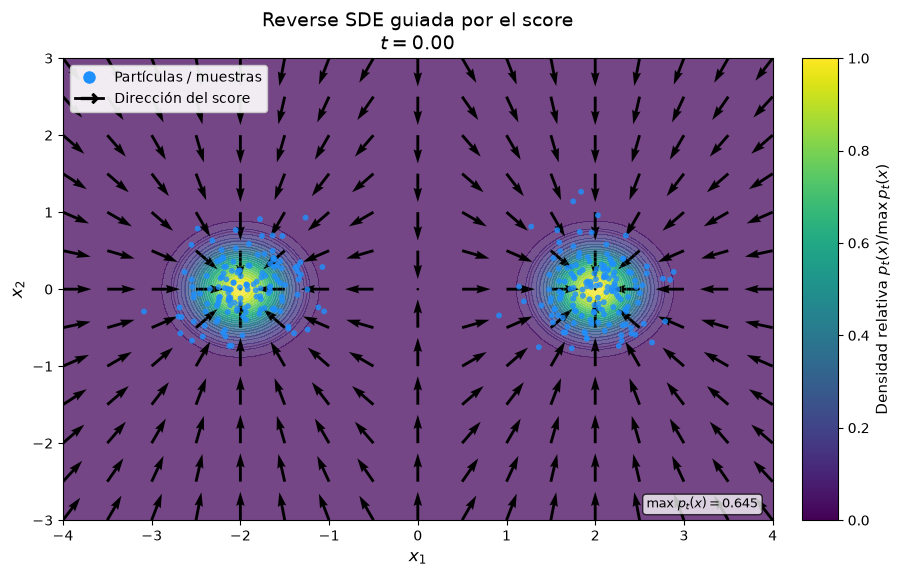

In [89]:
# ============================================================
# FIGURA
# ============================================================

fig = plt.figure(
    figsize=(10, 6)
)

gs = fig.add_gridspec(
    1,
    2,
    width_ratios=[20, 1],
    wspace=0.08
)

ax = fig.add_subplot(
    gs[0, 0]
)

cax = fig.add_subplot(
    gs[0, 1]
)


# ============================================================
# COLORBAR FIJA
#
# Ahora muestra DENSIDAD RELATIVA:
#
# rho_rel(x,t) = p_t(x) / max_x p_t(x)
#
# Por eso siempre va de 0 a 1.
# ============================================================

density_norm = Normalize(
    vmin=0,
    vmax=1
)

scalar_map = ScalarMappable(
    norm=density_norm,
    cmap="viridis"
)

scalar_map.set_array([])

cbar = fig.colorbar(
    scalar_map,
    cax=cax
)

cbar.set_label(
    r"Densidad relativa $p_t(x)/\max p_t(x)$",
    fontsize=11
)

cbar.set_ticks(
    np.linspace(0, 1, 6)
)


# ============================================================
# FRAMES QUE MOSTRAREMOS
# ============================================================

frame_indices = np.linspace(
    0,
    n_steps - 1,
    90,
    dtype=int
)


# ============================================================
# FUNCIÓN UPDATE
# ============================================================

def update(frame_number):

    # Limpiar únicamente el gráfico principal.
    # NO limpiar la colorbar.
    ax.clear()


    # --------------------------------------------------------
    # 1. Tiempo actual
    # --------------------------------------------------------

    step = frame_indices[
        frame_number
    ]

    t = times[
        step
    ]


    # ========================================================
    # 2. DENSIDAD p_t(x)
    # ========================================================

    density = density_mixture(
        grid_points,
        t
    )


    # --------------------------------------------------------
    # Normalizar la densidad de ESTE frame
    #
    # El valor máximo siempre será 1.
    # --------------------------------------------------------

    density_max = np.max(
        density
    )

    density_relative = (
        density
        /
        (density_max + 1e-12)
    )


    # --------------------------------------------------------
    # Dibujar densidad relativa
    # --------------------------------------------------------

    ax.contourf(
        XX,
        YY,
        density_relative,

        levels=np.linspace(
            0,
            1,
            25
        ),

        cmap="viridis",

        norm=density_norm,

        alpha=0.75
    )


    # --------------------------------------------------------
    # Curvas de nivel
    # --------------------------------------------------------

    ax.contour(
        XX,
        YY,
        density_relative,

        levels=np.linspace(
            0.1,
            0.9,
            9
        ),

        linewidths=0.7,
        alpha=0.5
    )


    # ========================================================
    # 3. CAMPO DEL SCORE
    #
    # s(x,t) = grad_x log p_t(x)
    # ========================================================

    score = score_mixture(
        score_grid,
        t
    )


    # --------------------------------------------------------
    # Normalizamos las flechas.
    #
    # Queremos mostrar DIRECCIÓN,
    # no magnitud.
    # --------------------------------------------------------

    norm = np.linalg.norm(
        score,
        axis=-1,
        keepdims=True
    )

    score_direction = (
        score
        /
        (norm + 1e-8)
    )


    # --------------------------------------------------------
    # Dibujar campo de score
    # --------------------------------------------------------

    ax.quiver(
        QX,
        QY,

        score_direction[..., 0],
        score_direction[..., 1],

        color="black",

        angles="xy",

        scale=25,

        width=0.004
    )


    # ========================================================
    # 4. PARTÍCULAS / MUESTRAS
    # ========================================================

    particles = trajectory[
        step
    ]

    ax.scatter(
        particles[:, 0],
        particles[:, 1],

        s=18,

        alpha=0.8,

        color="dodgerblue",

        edgecolors="none",

        zorder=3
    )


    # ========================================================
    # 5. CONVENCIÓN
    # ========================================================

    legend_elements = [
    Line2D(
        [0], [0],
        marker='o',
        color='none',
        markerfacecolor='dodgerblue',
        markeredgecolor='dodgerblue',
        markersize=8,
        label='Partículas / muestras'
    ),

    Line2D(
        [0], [0],
        color='black',
        linewidth=2,
        marker=r'$\rightarrow$',
        markersize=12,
        label='Dirección del score'
        )
    ]

    ax.legend(
        handles=legend_elements,
        loc='upper left',
        fontsize=10,
        frameon=True,
        framealpha=0.9,
        facecolor='white'
    )


    # ========================================================
    # 6. FORMATO
    # ========================================================

    ax.set_xlim(
        -4,
        4
    )

    ax.set_ylim(
        -3,
        3
    )

    ax.set_xlabel(
        r"$x_1$",
        fontsize=12
    )

    ax.set_ylabel(
        r"$x_2$",
        fontsize=12
    )


    ax.set_title(
        "Reverse SDE guiada por el score\n"
        +
        rf"$t={t:.2f}$",
        fontsize=14
    )


    # --------------------------------------------------------
    # Pequeño texto opcional con el máximo REAL de densidad
    #
    # Así no perdemos completamente la información absoluta.
    # --------------------------------------------------------

    ax.text(
        0.98,
        0.02,

        rf"$\max\,p_t(x)={density_max:.3f}$",

        transform=ax.transAxes,

        horizontalalignment="right",
        verticalalignment="bottom",

        fontsize=9,

        bbox=dict(
            boxstyle="round",
            facecolor="white",
            alpha=0.75
        )
    )


    return []


# ============================================================
# ANIMACIÓN
# ============================================================

animation = FuncAnimation(
    fig,
    update,

    frames=len(
        frame_indices
    ),

    interval=80,

    blit=False
)


# ============================================================
# GUARDAR GIF
# ============================================================

animation.save(
    "score_reverse_sde.gif",

    writer=PillowWriter(
        fps=12
    )
)


plt.show()